In [176]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split , StratifiedKFold , GridSearchCV
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score , classification_report , confusion_matrix

In [177]:
pd.set_option("display.max_columns" , None)
pd.set_option('display.float_format' , lambda x: '%3f' % x)

In [178]:
df = pd.read_csv("cancer.csv")

In [179]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.990000,10.380000,122.800000,1001.000000,0.118400,0.277600,0.300100,0.147100,0.241900,0.078710,1.095000,0.905300,8.589000,153.400000,0.006399,0.049040,0.053730,0.015870,0.030030,0.006193,25.380000,17.330000,184.600000,2019.000000,0.162200,0.665600,0.711900,0.265400,0.460100,0.118900,NaN
1,842517,M,20.570000,17.770000,132.900000,1326.000000,0.084740,0.078640,0.086900,0.070170,0.181200,0.056670,0.543500,0.733900,3.398000,74.080000,0.005225,0.013080,0.018600,0.013400,0.013890,0.003532,24.990000,23.410000,158.800000,1956.000000,0.123800,0.186600,0.241600,0.186000,0.275000,0.089020,NaN
2,84300903,M,19.690000,21.250000,130.000000,1203.000000,0.109600,0.159900,0.197400,0.127900,0.206900,0.059990,0.745600,0.786900,4.585000,94.030000,0.006150,0.040060,0.038320,0.020580,0.022500,0.004571,23.570000,25.530000,152.500000,1709.000000,0.144400,0.424500,0.450400,0.243000,0.361300,0.087580,NaN
3,84348301,M,11.420000,20.380000,77.580000,386.100000,0.142500,0.283900,0.241400,0.105200,0.259700,0.097440,0.495600,1.156000,3.445000,27.230000,0.009110,0.074580,0.056610,0.018670,0.059630,0.009208,14.910000,26.500000,98.870000,567.700000,0.209800,0.866300,0.686900,0.257500,0.663800,0.173000,NaN
4,84358402,M,20.290000,14.340000,135.100000,1297.000000,0.100300,0.132800,0.198000,0.104300,0.180900,0.058830,0.757200,0.781300,5.438000,94.440000,0.011490,0.024610,0.056880,0.018850,0.017560,0.005115,22.540000,16.670000,152.200000,1575.000000,0.137400,0.205000,0.400000,0.162500,0.236400,0.076780,NaN


In [180]:
df.columns

Index(['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean',
       'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32'],
      dtype='object')

In [181]:
df = df.drop(columns = 'Unnamed: 32')

In [182]:
df.shape

(569, 32)

In [183]:
df.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [184]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [185]:
for col in df.columns:
  print(col)
  print(df[col].value_counts().head(10))

id
id
92751       1
842302      1
842517      1
84300903    1
84348301    1
84358402    1
843786      1
844359      1
84458202    1
924084      1
Name: count, dtype: int64
diagnosis
diagnosis
B    357
M    212
Name: count, dtype: int64
radius_mean
radius_mean
12.340000    4
11.060000    3
10.260000    3
12.770000    3
13.050000    3
13.850000    3
12.180000    3
11.600000    3
13.000000    3
11.710000    3
Name: count, dtype: int64
texture_mean
texture_mean
16.840000    3
19.830000    3
15.700000    3
20.520000    3
18.220000    3
14.930000    3
18.900000    3
17.460000    3
16.850000    3
20.130000    2
Name: count, dtype: int64
perimeter_mean
perimeter_mean
82.610000     3
134.700000    3
87.760000     3
113.400000    2
120.200000    2
107.100000    2
79.190000     2
114.200000    2
58.790000     2
82.690000     2
Name: count, dtype: int64
area_mean
area_mean
512.200000     3
321.600000     2
582.700000     2
1138.000000    2
477.300000     2
372.700000     2
758.600000     2
559.200

In [186]:
df.duplicated().sum()

np.int64(0)

In [187]:
df['diagnosis'].value_counts(normalize=True)*100

,proportion
diagnosis,
B,62.741652
M,37.258348


In [188]:
from sklearn.preprocessing import LabelEncoder
label = LabelEncoder()

In [189]:
df['diagnosis'] = label.fit_transform(df['diagnosis'])
df['diagnosis']

,diagnosis
0,1
1,1
2,1
3,1
4,1
...,...
564,1
565,1
566,1
567,1


M = 1 , B = 0

In [190]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.990000,10.380000,122.800000,1001.000000,0.118400,0.277600,0.300100,0.147100,0.241900,0.078710,1.095000,0.905300,8.589000,153.400000,0.006399,0.049040,0.053730,0.015870,0.030030,0.006193,25.380000,17.330000,184.600000,2019.000000,0.162200,0.665600,0.711900,0.265400,0.460100,0.118900
1,842517,1,20.570000,17.770000,132.900000,1326.000000,0.084740,0.078640,0.086900,0.070170,0.181200,0.056670,0.543500,0.733900,3.398000,74.080000,0.005225,0.013080,0.018600,0.013400,0.013890,0.003532,24.990000,23.410000,158.800000,1956.000000,0.123800,0.186600,0.241600,0.186000,0.275000,0.089020
2,84300903,1,19.690000,21.250000,130.000000,1203.000000,0.109600,0.159900,0.197400,0.127900,0.206900,0.059990,0.745600,0.786900,4.585000,94.030000,0.006150,0.040060,0.038320,0.020580,0.022500,0.004571,23.570000,25.530000,152.500000,1709.000000,0.144400,0.424500,0.450400,0.243000,0.361300,0.087580
3,84348301,1,11.420000,20.380000,77.580000,386.100000,0.142500,0.283900,0.241400,0.105200,0.259700,0.097440,0.495600,1.156000,3.445000,27.230000,0.009110,0.074580,0.056610,0.018670,0.059630,0.009208,14.910000,26.500000,98.870000,567.700000,0.209800,0.866300,0.686900,0.257500,0.663800,0.173000
4,84358402,1,20.290000,14.340000,135.100000,1297.000000,0.100300,0.132800,0.198000,0.104300,0.180900,0.058830,0.757200,0.781300,5.438000,94.440000,0.011490,0.024610,0.056880,0.018850,0.017560,0.005115,22.540000,16.670000,152.200000,1575.000000,0.137400,0.205000,0.400000,0.162500,0.236400,0.076780


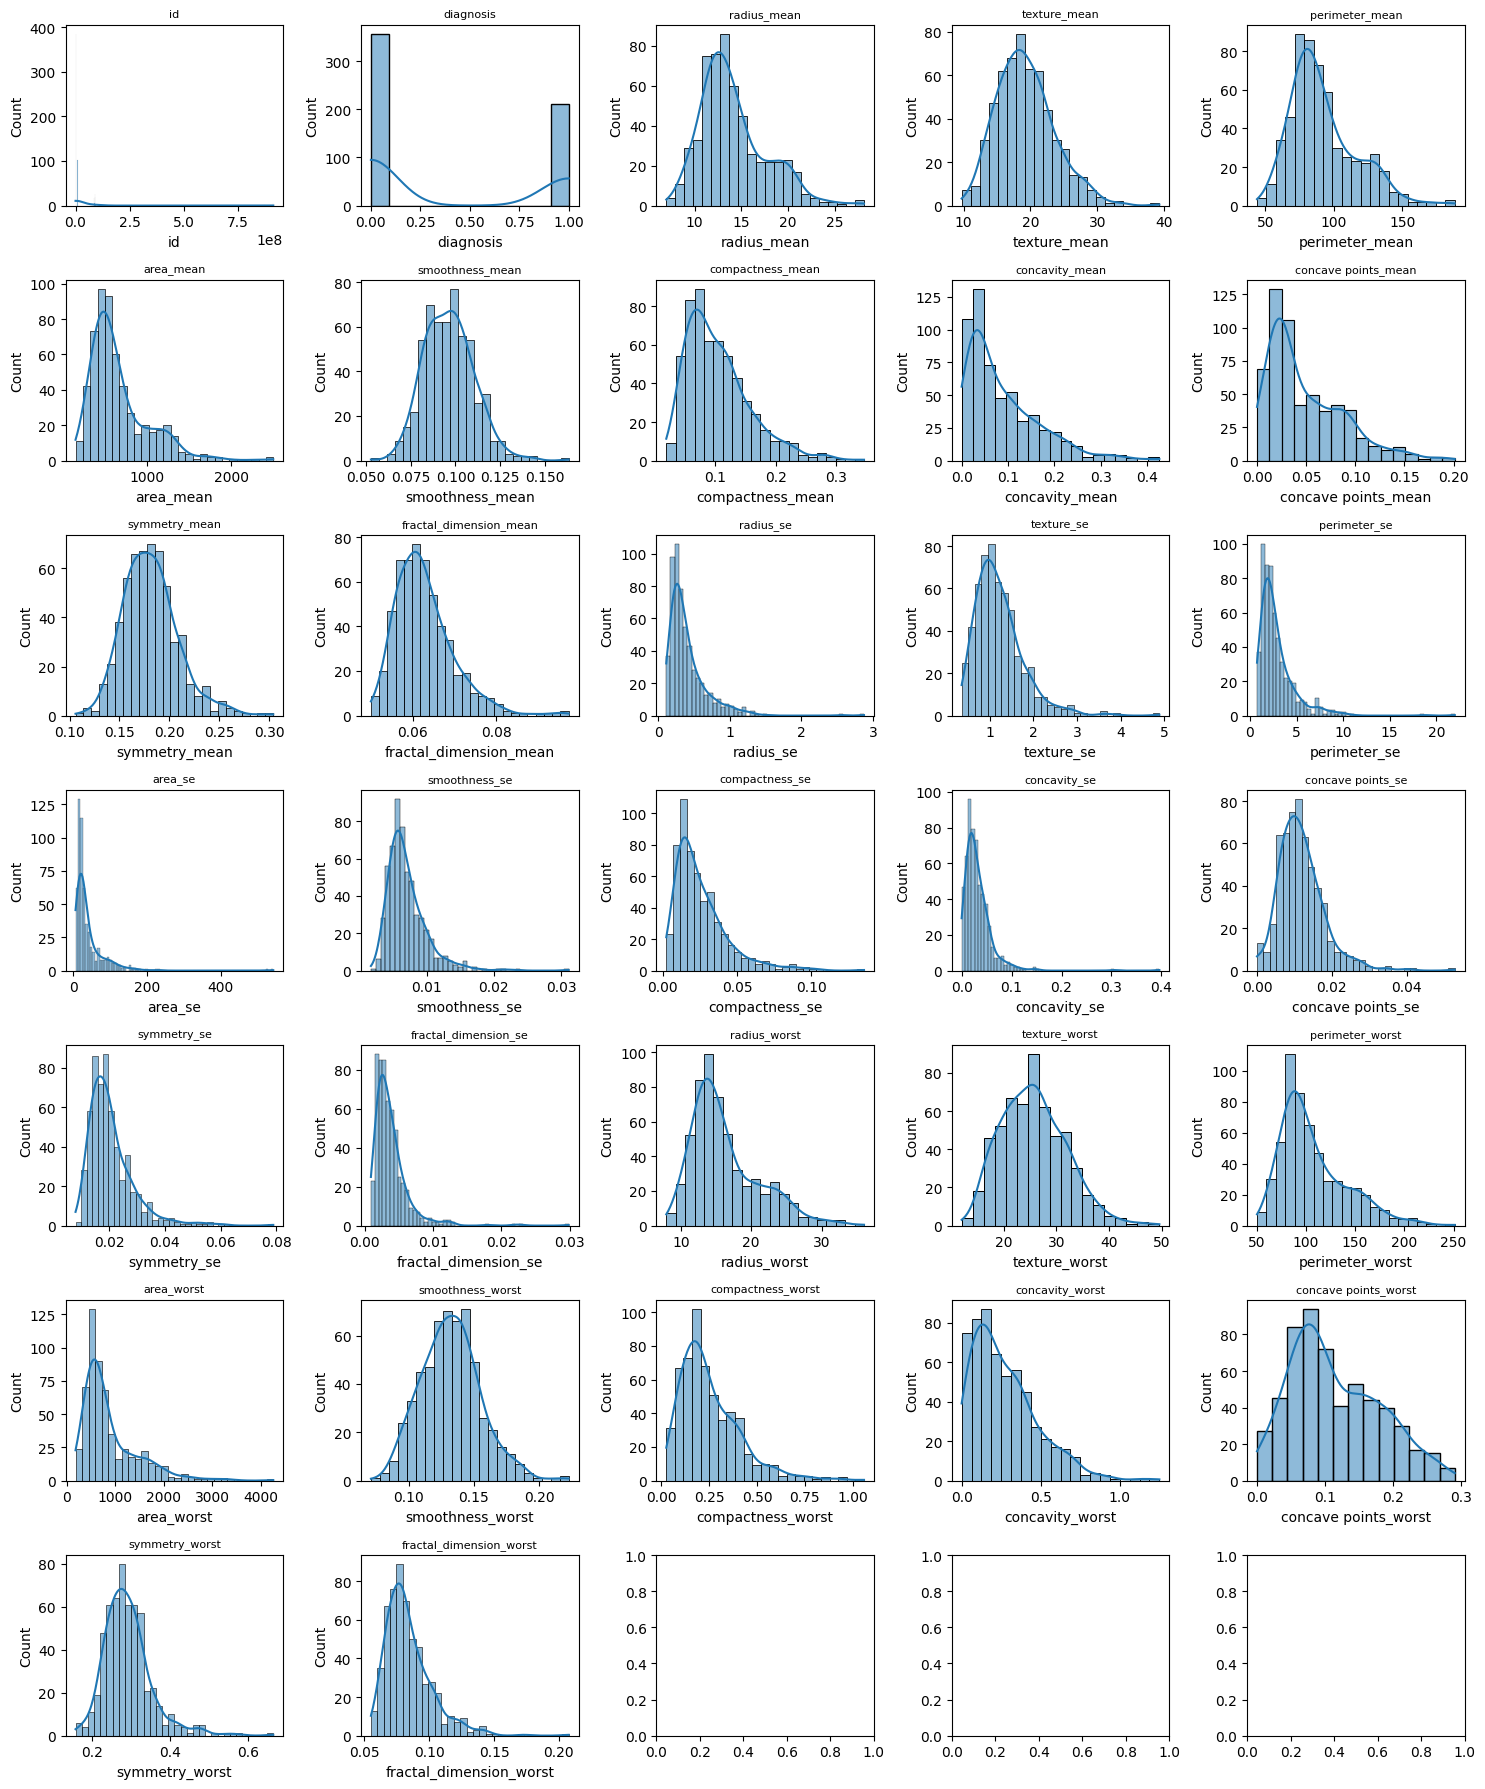

In [191]:
fig , axes = plt.subplots(7 , 5 , figsize =(15 , 18))
axes = axes.flatten()

for i , col in enumerate(df.columns):
  sns.histplot(df[col] , kde =True , ax = axes[i])
  axes[i].set_title(col , fontsize = 8)

plt.tight_layout()
plt.show()


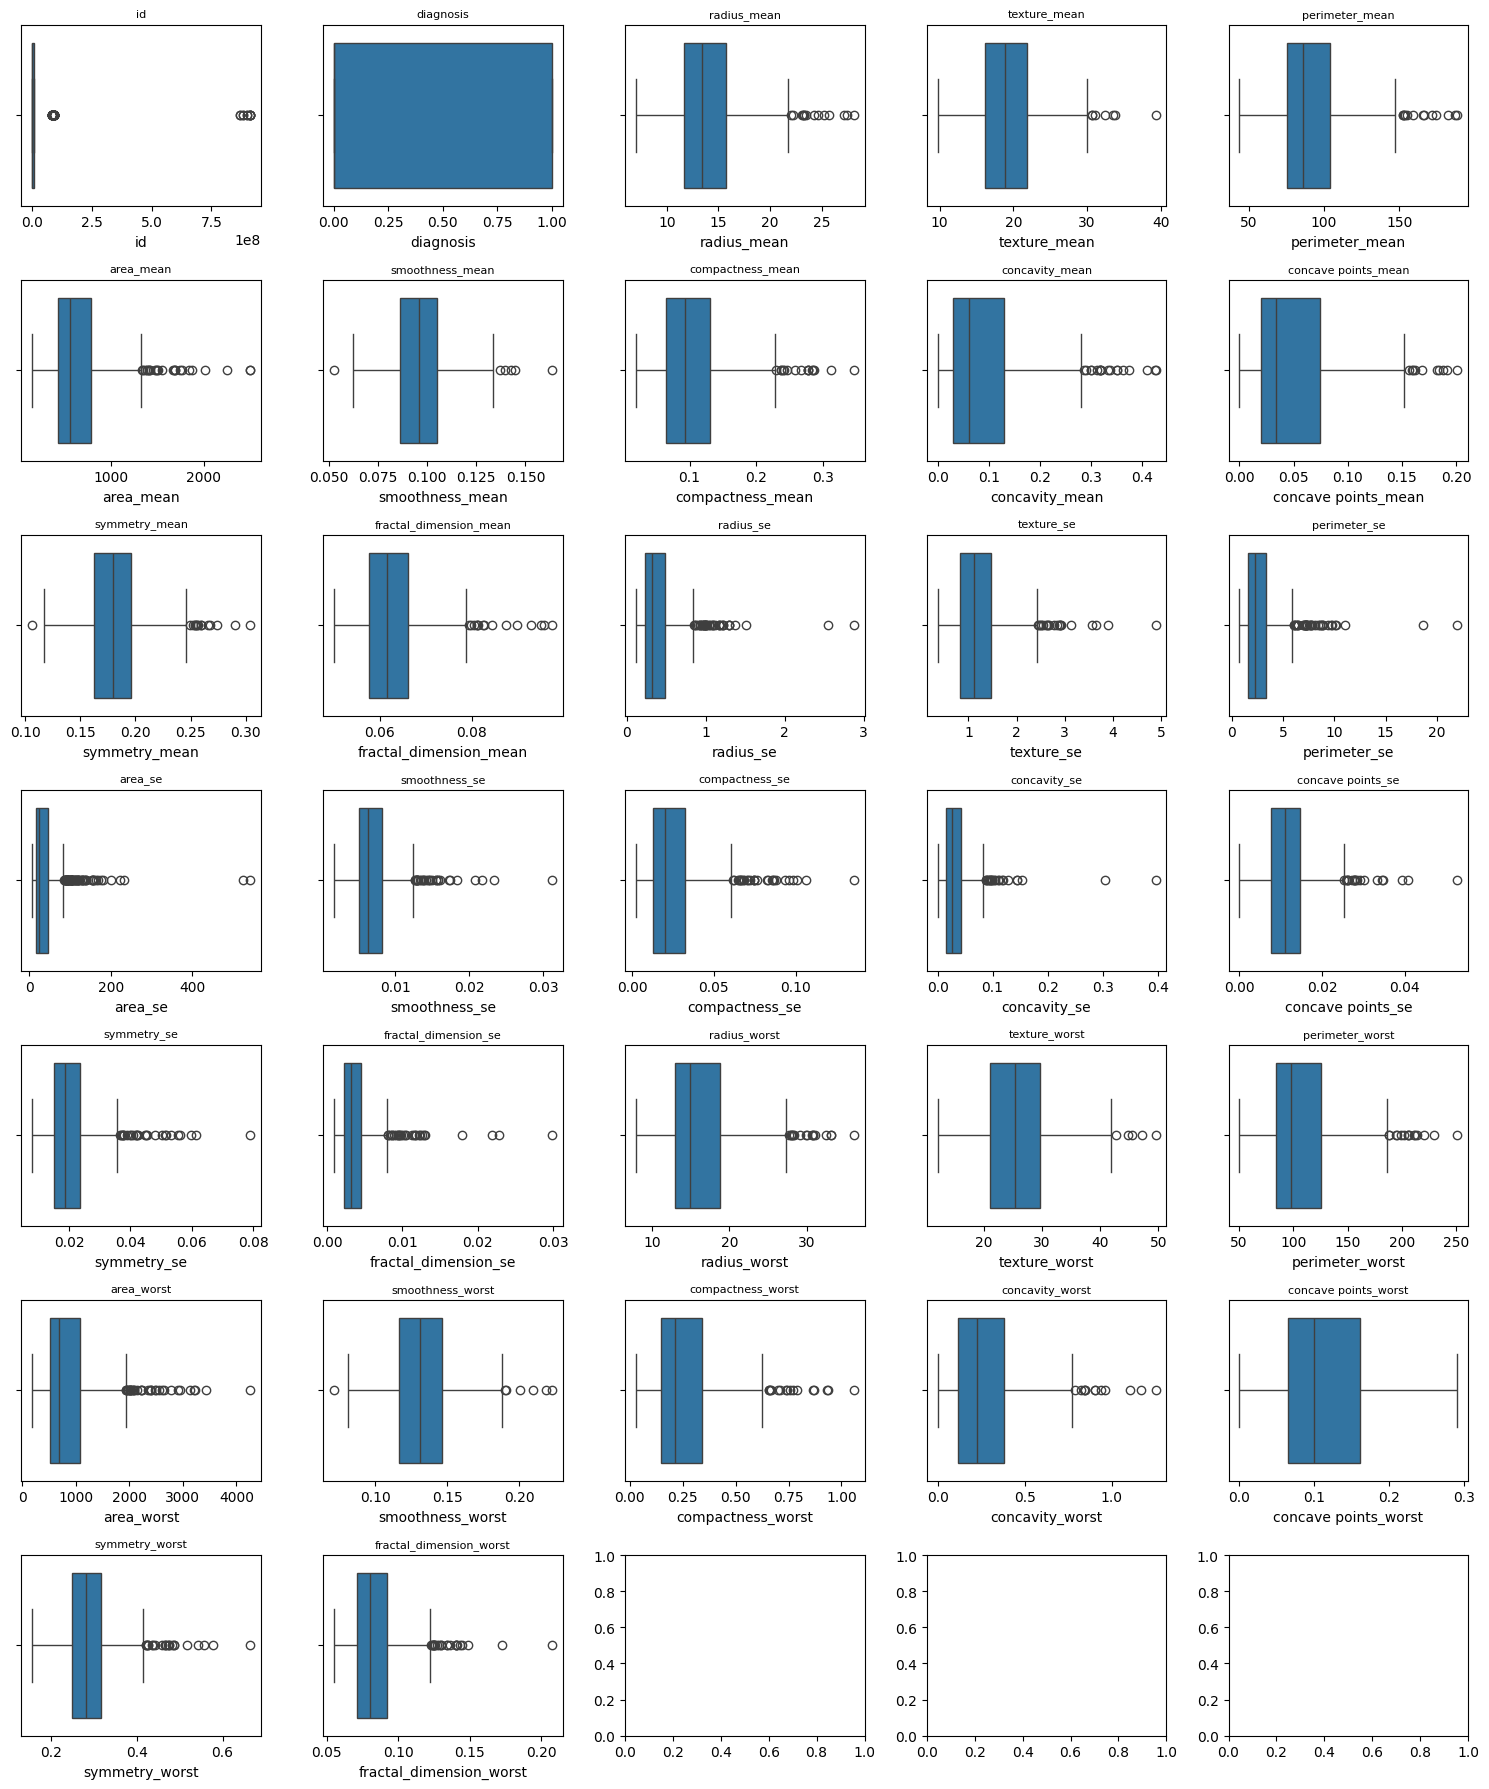

In [192]:
fig , axes = plt.subplots(7 , 5 , figsize =(15 , 18))
axes = axes.flatten()

for i , col in enumerate(df.columns):
  sns.boxplot(x = df[col], ax = axes[i])
  axes[i].set_title(col , fontsize = 8)

plt.tight_layout()
plt.show()


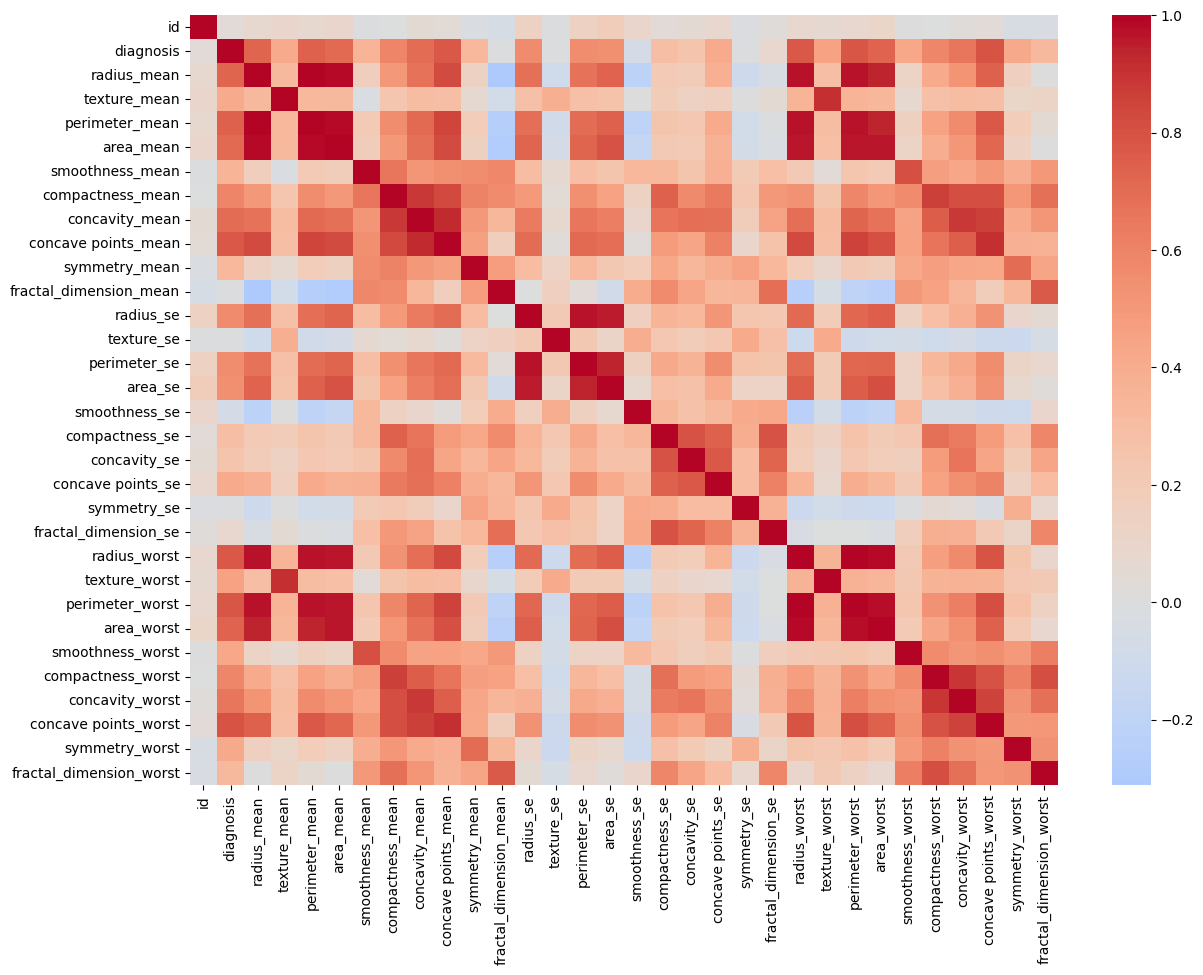

In [193]:
plt.figure(figsize = (14 , 10))
sns.heatmap(
    df.corr(),
    cmap = "coolwarm",
    center = 0
)
plt.show()

In [194]:
X = df.drop(columns = 'diagnosis')
X = df.drop(columns = 'id')

In [195]:
y = df['diagnosis']

In [196]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [197]:
scaler = StandardScaler()

In [198]:
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [199]:
model = LogisticRegression()

In [200]:
model.fit(X_train_scaled , y_train)

LogisticRegression()

In [201]:
y_test_pred_LR = model.predict(X_test_scaled)

In [202]:
accuracy = accuracy_score(y_test , y_test_pred_LR)
accuracy

1.0

In [203]:
print(classification_report(y_test , y_test_pred_LR))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        71
           1       1.00      1.00      1.00        43

    accuracy                           1.00       114
   macro avg       1.00      1.00      1.00       114
weighted avg       1.00      1.00      1.00       114



In [204]:
print(confusion_matrix(y_test , y_test_pred_LR))

[[71  0]
 [ 0 43]]


In [205]:
model_scv = SVC()

In [206]:
model_scv.fit(X_train_scaled , y_train)

SVC()

In [207]:
y_test_pred_SVC = model_scv.predict(X_test_scaled)

In [208]:
accuracy = accuracy_score(y_test , y_test_pred_SVC)
accuracy

1.0

<h1>With Pipeline<h1>


In [209]:
pipeline  = Pipeline(
    [
        ("scaler" , StandardScaler()),
        ("pca" , PCA()),
        ("model" , SVC(kernel = 'rbf'))
    ]
)

In [210]:
param_grid = [
    {
        "pca__n_components" : [10 , 15 , 20 , 25 , 30],
        "model__C": [0.1 , 1 , 10 , 100 , 1000],
        "model__gamma": [0.001 , 0.01 , 0.1 , 1 , "scale"]
    }
]

In [211]:
k = 5
cv = StratifiedKFold(n_splits = k , shuffle = True , random_state = 42)

In [212]:
grid_Search = GridSearchCV(
    estimator = pipeline,
    param_grid = param_grid,
    scoring = "recall",
    cv = cv,
    n_jobs = -1
)

In [213]:
grid_Search.fit(X_train , y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                       ('pca', PCA()), ('model', SVC())]),
             n_jobs=-1,
             param_grid=[{'model__C': [0.1, 1, 10, 100, 1000],
                          'model__gamma': [0.001, 0.01, 0.1, 1, 'scale'],
                          'pca__n_components': [10, 15, 20, 25, 30]}],
             scoring='recall')

In [214]:
print(grid_Search.best_params_)
print(grid_Search.best_score_)

{'model__C': 1, 'model__gamma': 0.01, 'pca__n_components': 15}
1.0


In [215]:
y_pred_test_svc = grid_Search.predict(X_test)

In [216]:
best_params = Pipeline(
    [
        ("scaler" , StandardScaler()),
        ("pca" , PCA(n_components=10)),
        ("model" , SVC(kernel = 'rbf' , C=1000 , gamma=0.01))
    ]
)

In [217]:
best_params.fit(X_train , y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('pca', PCA(n_components=10)),
                ('model', SVC(C=1000, gamma=0.01))])

In [218]:
y_train_pred = best_params.predict(X_train)

In [219]:
train_acc = accuracy_score(y_train , y_train_pred)
train_acc

1.0

In [220]:
y_test_pred = best_params.predict(X_test)

In [221]:
test_acc = accuracy_score(y_test , y_test_pred)
test_acc

0.9736842105263158

In [222]:
cm_train = confusion_matrix(y_train , y_train_pred)
cm_train

array([[286,   0],
       [  0, 169]])

In [223]:
cm_test = confusion_matrix(y_test, y_test_pred)
cm_test

array([[69,  2],
       [ 1, 42]])

Build a predictive system

In [236]:
def predictive_system(input_feature):
  prediction = best_params.predict([input_feature])
  if(prediction == 1):
    print("Malignant")
  else:
    print("Benign")

In [225]:
X_train.head(10)

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
68,0,9.029000,17.330000,58.790000,250.500000,0.106600,0.141300,0.313000,0.043750,0.211100,0.080460,0.327400,1.194000,1.885000,17.670000,0.009549,0.086060,0.303800,0.033220,0.041970,0.009559,10.310000,22.650000,65.500000,324.700000,0.148200,0.436500,1.252000,0.175000,0.422800,0.117500
181,1,21.090000,26.570000,142.700000,1311.000000,0.114100,0.283200,0.248700,0.149600,0.239500,0.073980,0.629800,0.762900,4.414000,81.460000,0.004253,0.047590,0.038720,0.015670,0.017980,0.005295,26.680000,33.480000,176.500000,2089.000000,0.149100,0.758400,0.678000,0.290300,0.409800,0.128400
63,0,9.173000,13.860000,59.200000,260.900000,0.077210,0.087510,0.059880,0.021800,0.234100,0.069630,0.409800,2.265000,2.608000,23.520000,0.008738,0.039380,0.043120,0.015600,0.041920,0.005822,10.010000,19.230000,65.590000,310.100000,0.098360,0.167800,0.139700,0.050870,0.328200,0.084900
248,0,10.650000,25.220000,68.010000,347.000000,0.096570,0.072340,0.023790,0.016150,0.189700,0.063290,0.249700,1.493000,1.497000,16.640000,0.007189,0.010350,0.010810,0.006245,0.021580,0.002619,12.250000,35.190000,77.980000,455.700000,0.149900,0.139800,0.112500,0.061360,0.340900,0.081470
60,0,10.170000,14.880000,64.550000,311.900000,0.113400,0.080610,0.010840,0.012900,0.274300,0.069600,0.515800,1.441000,3.312000,34.620000,0.007514,0.010990,0.007665,0.008193,0.041830,0.005953,11.020000,17.450000,69.860000,368.600000,0.127500,0.098660,0.021680,0.025790,0.355700,0.080200
15,1,14.540000,27.540000,96.730000,658.800000,0.113900,0.159500,0.163900,0.073640,0.230300,0.070770,0.370000,1.033000,2.879000,32.550000,0.005607,0.042400,0.047410,0.010900,0.018570,0.005466,17.460000,37.130000,124.100000,943.200000,0.167800,0.657700,0.702600,0.171200,0.421800,0.134100
290,0,14.410000,19.730000,96.030000,651.000000,0.087570,0.167600,0.136200,0.066020,0.171400,0.071920,0.881100,1.770000,4.360000,77.110000,0.007762,0.106400,0.099600,0.027710,0.040770,0.022860,15.770000,22.130000,101.700000,767.300000,0.099830,0.247200,0.222000,0.102100,0.227200,0.087990
137,0,11.430000,15.390000,73.060000,399.800000,0.096390,0.068890,0.035030,0.028750,0.173400,0.058650,0.175900,0.993800,1.143000,12.670000,0.005133,0.015210,0.014340,0.008602,0.015010,0.001588,12.320000,22.020000,79.930000,462.000000,0.119000,0.164800,0.139900,0.084760,0.267600,0.067650
155,0,12.250000,17.940000,78.270000,460.300000,0.086540,0.066790,0.038850,0.023310,0.197000,0.062280,0.220000,0.982300,1.484000,16.510000,0.005518,0.015620,0.019940,0.007924,0.017990,0.002484,13.590000,25.220000,86.600000,564.200000,0.121700,0.178800,0.194300,0.082110,0.311300,0.081320
517,1,19.890000,20.260000,130.500000,1214.000000,0.103700,0.131000,0.141100,0.094310,0.180200,0.061880,0.507900,0.873700,3.654000,59.700000,0.005089,0.023030,0.030520,0.011780,0.010570,0.003391,23.730000,25.230000,160.500000,1646.000000,0.141700,0.330900,0.418500,0.161300,0.254900,0.091360


In [226]:
y_train.head(10)

,diagnosis
68,0
181,1
63,0
248,0
60,0
15,1
290,0
137,0
155,0
517,1


In [239]:
y_input = X_train.loc[290].tolist()
predictive_system(y_input)

Benign


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
